In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [2]:
model = YOLO('yolov8n-pose.pt')

names = ['nose', 'l_eye', 'r_eye', 'l_ear', 'r_ear', 'l_shoulder', 'r_shoulder', 'l_elbow', 'r_elbow',
         'l_wrist', 'r_wrist', 'l_hip', 'r_hip', 'l_knee', 'r_knee', 'l_ankle', 'r_ankle']
skeleton = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12),
            (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]

In [3]:
def angle(a, b, c):
    ba, bc = a - b, c - b
    cos = ba @ bc / (np.linalg.norm(ba) * np.linalg.norm(bc))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))


def draw_pose(frame, min_conf=0.5):
    people = []
    r = model(frame, verbose=False)[0]
    for xy, cf in zip(r.keypoints.xy.numpy(), r.keypoints.conf.numpy()):
        for i, j in skeleton:
            if cf[i] > min_conf and cf[j] > min_conf:
                cv2.line(frame, tuple(xy[i].astype(int)), tuple(xy[j].astype(int)), (0, 255, 0), 2)
        for p, c in zip(xy, cf):
            if c > min_conf:
                cv2.circle(frame, tuple(p.astype(int)), 4, (0, 0, 255), -1)

        for side, (s, e, w) in {'L': (5, 7, 9), 'R': (6, 8, 10)}.items():
            if min(cf[s], cf[e], cf[w]) > min_conf:
                deg = angle(xy[s], xy[e], xy[w])
                cv2.putText(frame, f'{side} {deg:.0f}', (int(xy[e][0]) + 6, int(xy[e][1])), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)

        people.append({n: xy[k].round(1).tolist() for k, n in enumerate(names) if cf[k] > min_conf})
    return frame, people

4 people
nose [143.8000030517578, 443.5]
l_eye [149.10000610351562, 435.20001220703125]
r_eye [133.6999969482422, 434.70001220703125]
r_ear [107.30000305175781, 439.0]
l_shoulder [163.1999969482422, 494.29998779296875]
r_shoulder [88.69999694824219, 496.3999938964844]


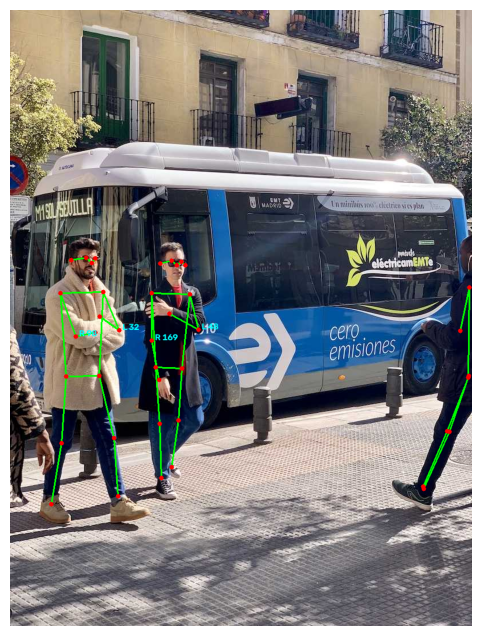

In [4]:
img = cv2.imread('bus.jpg')
img, people = draw_pose(img)
print(len(people), 'people')
for k, v in list(people[0].items())[:6]:
    print(k, v)

plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [5]:
os.makedirs('output', exist_ok=True)
cv2.imwrite('output/task5_pose.png', img)

True

In [6]:
webcam = False

if webcam:
    cap = cv2.VideoCapture(0)
    cap.set(3, 640)
    cap.set(4, 480)

    while True:
        success, frame = cap.read()
        frame, people = draw_pose(frame)
        if people and 'r_wrist' in people[0]:
            cv2.putText(frame, f"r_wrist {people[0]['r_wrist']}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

        cv2.imshow('Pose', frame)
        if cv2.waitKey(1) == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

Used yolov8n-pose from ultralytics instead of mediapipe since the mp.solutions api from the manual is gone in newer mediapipe versions. It gives 17 COCO keypoints per person. Skeleton is drawn from the keypoint pairs and only keypoints with confidence above 0.5 are used. Elbow angle is the angle at the elbow between the shoulder and wrist vectors, so a straight arm is close to 180. In the webcam loop the wrist coordinates are printed on the frame and update every frame. Tested on bus.jpg only, 4 people found, not on a live camera.